# Reto S12 · «Escuchar al cliente» · reseñas · equipo «Las Palmeras» (entrega de referencia)

**Pregunta del cliente (TurisData Canarias):** *¿qué opinan de nosotros y qué hacemos primero?* Este cuaderno saca las cifras del informe de reseñas.

**Qué hace:** reparto del sentimiento, un clasificador (regresión logística con TF-IDF) **evaluado en prueba** con exactitud y matriz de confusión, comparado con Naive Bayes y con «decir siempre la clase mayoritaria»; los temas más criticados y más valorados con su ejemplo real; tres citas con su `id_resena`; una comprobación de datos personales; el gráfico `grafico_resenas.png`.

**Cómo se ejecuta:** *Entorno de ejecución → Reiniciar y ejecutar todo* (segundos, sin internet si la carpeta `datos/` ya existe). `SEMILLA = 42`.

**Sin fuga de datos:** el vectorizador TF-IDF está **dentro** del `pipeline` y se ajusta solo con las reseñas de entrenamiento; si se ajustara con todas, el vocabulario de prueba «se colaría» en el entrenamiento y la exactitud saldría más alta de lo real.

## 0. Preparación

In [1]:
import os, urllib.request

BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"

def dato(nombre):
    """Devuelve la ruta local de un archivo de datos del curso (lo descarga si no está)."""
    for carpeta in ("datos", "../datos", "../../datos"):
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta):
            return ruta
    os.makedirs("datos", exist_ok=True)
    ruta = os.path.join("datos", nombre)
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    return ruta

import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEMILLA = 42
np.random.seed(SEMILLA)
plt.rcParams.update({"figure.figsize": (8, 3.5), "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False})
print("Listo ✔")

Listo ✔


## 1. Los datos y el reparto del sentimiento

In [2]:
resenas = pd.read_csv(dato("resenas.csv"))
ORDEN = ["positivo", "neutro", "negativo"]
reparto = resenas["sentimiento"].value_counts(normalize=True).mul(100).round(1).reindex(ORDEN)
print(resenas.shape, "reseñas (datos sintéticos)")
print(reparto.to_string())
print("Nota media por sentimiento:", resenas.groupby("sentimiento")["nota"].mean().round(2).reindex(ORDEN).to_dict())

(1500, 5) reseñas (datos sintéticos)
sentimiento
positivo    46.9
neutro      21.2
negativo    31.9
Nota media por sentimiento: {'positivo': 4.51, 'neutro': 3.0, 'negativo': 1.49}


## 2. Limpiar y tokenizar

In [3]:
def limpiar(texto):
    texto = texto.lower()
    texto = re.sub(r"[^a-záéíóúüñ\s]", " ", texto)
    return " ".join(texto.split())

PALABRAS_VACIAS = {"a", "al", "con", "de", "del", "el", "en", "es", "esta", "estaba", "era", "fue", "la", "las", "lo", "los",
                   "me", "mi", "muy", "nos", "para", "por", "que", "se", "su", "un", "una", "y", "o", "u", "e"}

def tokenizar(texto):
    return [t for t in limpiar(texto).split() if t not in PALABRAS_VACIAS]

assert limpiar("¡Qué BUENO!...  Sí") == "qué bueno sí"
print(repr(limpiar("¡Qué BUENO!...  Sí")), "·", tokenizar("La limpieza de la habitación era impecable!"))

'qué bueno sí' · ['limpieza', 'habitación', 'impecable']


## 3. Clasificador de sentimiento, evaluado en prueba
El vectorizador va dentro del `pipeline`: se ajusta **solo** con el entrenamiento (sin fuga).

In [4]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score

X_ent, X_test, y_ent, y_test = train_test_split(resenas["texto"], resenas["sentimiento"], test_size=0.25,
                                                stratify=resenas["sentimiento"], random_state=SEMILLA)
print(len(X_ent), "para entrenar,", len(X_test), "para probar (la prueba solo se mira para evaluar)")

modelo_lr = make_pipeline(TfidfVectorizer(preprocessor=limpiar), LogisticRegression(max_iter=1000)).fit(X_ent, y_ent)
modelo_nb = make_pipeline(CountVectorizer(preprocessor=limpiar), MultinomialNB()).fit(X_ent, y_ent)
acc_lr = accuracy_score(y_test, modelo_lr.predict(X_test))
acc_nb = accuracy_score(y_test, modelo_nb.predict(X_test))
acc_mayoritaria = float(y_test.value_counts(normalize=True).max())
print(f"Regresión logística + TF-IDF  : {acc_lr:.3f}")
print(f"Naive Bayes + bolsa de palabras: {acc_nb:.3f}")
print(f"Siempre la clase mayoritaria   : {acc_mayoritaria:.3f}")
assert acc_lr > acc_mayoritaria and acc_nb > acc_mayoritaria
print("✔ El clasificador supera a decir siempre la clase mayoritaria")

1125 para entrenar, 375 para probar (la prueba solo se mira para evaluar)
Regresión logística + TF-IDF  : 0.992
Naive Bayes + bolsa de palabras: 0.989
Siempre la clase mayoritaria   : 0.469
✔ El clasificador supera a decir siempre la clase mayoritaria


### Matriz de confusión
Las filas son lo real y las columnas lo que dice el modelo. Lo que está fuera de la diagonal son los errores.

              precision    recall  f1-score   support

    positivo       1.00      1.00      1.00       176
      neutro       1.00      0.96      0.98        79
    negativo       0.98      1.00      0.99       120

    accuracy                           0.99       375
   macro avg       0.99      0.99      0.99       375
weighted avg       0.99      0.99      0.99       375

Matriz de confusión (filas = real, columnas = predicho; orden positivo, neutro, negativo):
[[176   0   0]
 [  0  76   3]
 [  0   0 120]]


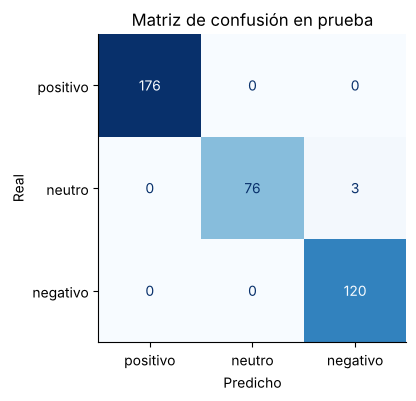

In [5]:
pred_test = modelo_lr.predict(X_test)
informe_clf = classification_report(y_test, pred_test, labels=ORDEN, output_dict=True, zero_division=0)
print(classification_report(y_test, pred_test, labels=ORDEN, zero_division=0))
matriz = confusion_matrix(y_test, pred_test, labels=ORDEN)
print("Matriz de confusión (filas = real, columnas = predicho; orden positivo, neutro, negativo):")
print(matriz)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(matriz, display_labels=ORDEN).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Matriz de confusión en prueba"); ax.set_xlabel("Predicho"); ax.set_ylabel("Real"); ax.grid(False)
plt.show()

### Límite conocido: la negación
Una bolsa de palabras no entiende el orden; se prueba con frases con y sin «no».

In [6]:
pruebas = ["La limpieza es impecable", "La limpieza no es impecable", "El personal fue borde", "El personal no fue borde",
           "Vistas increíbles pero un ruido constante"]
predichas = modelo_lr.predict(pruebas)
for f, p in zip(pruebas, predichas):
    print(f"{p:9s} ← {f}")
falla_negacion = predichas[1] == "positivo"
print("¿Falla con la negación («no es impecable»)?", falla_negacion)

positivo  ← La limpieza es impecable
positivo  ← La limpieza no es impecable
negativo  ← El personal fue borde
negativo  ← El personal no fue borde
negativo  ← Vistas increíbles pero un ruido constante
¿Falla con la negación («no es impecable»)? True


## 4. Temas: qué se critica y qué se valora
Detector por diccionario de palabras. «Menciona el tema» **no** es «opina mal de ese tema»: una reseña negativa puede hablar bien del desayuno y mal del ruido.

In [7]:
TEMAS = {
    "limpieza":  ["limpi", "sucia", "sucio", "pelos", "sábanas", "toallas"],
    "ruido":     ["ruid", "silencio", "música", "dormir", "oye", "tranquilo"],
    "desayuno":  ["desayuno", "café", "buffet", "colas"],
    "personal":  ["personal", "recepción", "recepcionista", "trato", "borde", "atendía", "ayudó", "tardaron"],
    "ubicacion": ["ubicación", "situado", "lejos", "centro", "playa", "vistas", "coche", "zona"],
    "precio":    ["precio", "caro", "cuesta", "extras", "cobran", "compensa"],
}

def detectar_temas(texto):
    t = limpiar(texto)
    return sorted(tema for tema, claves in TEMAS.items() if any(c in t for c in claves))

resenas["temas_detectados"] = resenas["texto"].apply(detectar_temas)
resenas["temas_reales"] = resenas["temas"].fillna("").apply(lambda s: [x for x in s.split(",") if x])

def f1_tema(tema):
    real = resenas["temas_reales"].apply(lambda l: tema in l)
    pred = resenas["temas_detectados"].apply(lambda l: tema in l)
    return f1_score(real, pred)

f1_por_tema = pd.Series({t: f1_tema(t) for t in TEMAS}).sort_values()
print("F1 del detector de temas (contra los temas anotados):")
print(f1_por_tema.round(2).to_string())

neg = resenas[resenas["sentimiento"] == "negativo"]
pos = resenas[resenas["sentimiento"] == "positivo"]
quejas = neg["temas_detectados"].explode().value_counts()
elogios = pos["temas_detectados"].explode().value_counts()
tabla_temas = pd.DataFrame({"negativas": quejas, "positivas": elogios}).fillna(0).astype(int)
tabla_temas["% negativas"] = (100 * tabla_temas["negativas"] / (tabla_temas["negativas"] + tabla_temas["positivas"])).round(1)
tabla_temas = tabla_temas.sort_values("negativas", ascending=False)
print("\nReseñas que mencionan cada tema (% negativas = negativas / (negativas + positivas)):")
print(tabla_temas.to_string())
print(f"\nTemas más mencionados en las {len(neg)} reseñas NEGATIVAS:", quejas.head(3).to_dict())
print(f"Temas más mencionados en las {len(pos)} reseñas POSITIVAS :", elogios.head(3).to_dict())

F1 del detector de temas (contra los temas anotados):
ruido        0.94
limpieza     1.00
desayuno     1.00
personal     1.00
ubicacion    1.00
precio       1.00

Reseñas que mencionan cada tema (% negativas = negativas / (negativas + positivas)):


                  negativas  positivas  % negativas
temas_detectados                                   
ruido                   201        244         45.2
limpieza                171        249         40.7
precio                  165        243         40.4
desayuno                162        237         40.6
ubicacion               160        244         39.6
personal                147        218         40.3

Temas más mencionados en las 478 reseñas NEGATIVAS: {'ruido': 201, 'limpieza': 171, 'precio': 165}
Temas más mencionados en las 704 reseñas POSITIVAS : {'limpieza': 249, 'ruido': 244, 'ubicacion': 244}


### Un ejemplo real de cada tema y tres citas

In [8]:
def ejemplo(tema, sentimiento, max_palabras=14):
    """Primera reseña (por id) de ese sentimiento que habla SOLO de ese tema y es corta: sirve de ejemplo real."""
    sub = resenas[(resenas["sentimiento"] == sentimiento) & (resenas["temas_detectados"].apply(lambda l: l == [tema]))]
    sub = sub[sub["texto"].str.split().str.len() <= max_palabras].sort_values("id_resena")
    fila = sub.iloc[0]
    return int(fila["id_resena"]), fila["texto"]

criticados = [(t, int(n), *ejemplo(t, "negativo")) for t, n in quejas.head(3).items()]
valorados = [(t, int(n), *ejemplo(t, "positivo")) for t, n in elogios.head(3).items()]
print("Más criticados:")
for t, n, i, x in criticados:
    print(f"- {t}: {n} reseñas negativas lo mencionan · ejemplo (id {i}): «{x}»")
print("Más valorados:")
for t, n, i, x in valorados:
    print(f"- {t}: {n} reseñas positivas lo mencionan · ejemplo (id {i}): «{x}»")

# Tres citas reales con su id_resena: una por sentimiento (la negativa y la positiva, del tema principal)
neutras = resenas[(resenas["sentimiento"] == "neutro") & (resenas["temas_detectados"].apply(len) == 0) & (resenas["texto"].str.split().str.len().between(5, 12))].sort_values("id_resena")
citas = [("positivo", *ejemplo(elogios.index[0], "positivo")), ("neutro", int(neutras.iloc[0]["id_resena"]), neutras.iloc[0]["texto"]),
         ("negativo", *ejemplo(quejas.index[0], "negativo"))]
for s, i, x in citas:
    print(f"{s:9s} id_resena {i}: «{x}»")

Más criticados:
- ruido: 201 reseñas negativas lo mencionan · ejemplo (id 51): «Fuimos por trabajo. Se oye todo de la habitación de al lado.»
- limpieza: 171 reseñas negativas lo mencionan · ejemplo (id 13): «Viajamos en familia. La limpieza deja mucho que desear...»
- precio: 165 reseñas negativas lo mencionan · ejemplo (id 2): «Pasamos una semana aquí. Cobran extras por todo...»
Más valorados:
- limpieza: 249 reseñas positivas lo mencionan · ejemplo (id 41): «Viajamos en familia. Todo estaba muy limpio.»
- ruido: 244 reseñas positivas lo mencionan · ejemplo (id 26): «Silencio total por las noches!»
- ubicacion: 244 reseñas positivas lo mencionan · ejemplo (id 149): «Viajamos en familia. Vistas al mar increíbles!»
positivo  id_resena 41: «Viajamos en familia. Todo estaba muy limpio.»
neutro    id_resena 12: «En general, Cumple lo básico!»
negativo  id_resena 51: «Fuimos por trabajo. Se oye todo de la habitación de al lado.»


## 5. Datos personales
Se comprueba antes de publicar citas.

In [9]:
# Datos personales: ¿hay correos, teléfonos o DNI en las reseñas? (se mira antes de citar nada)
PATRONES_PII = {"correo": r"[\w.+-]+@[\w-]+\.[\w.]+",
                "teléfono": r"(?<!\d)(?:\+34[\s.-]?)?[6-9]\d{2}[\s.-]?\d{3}[\s.-]?\d{3}(?!\d)",
                "DNI/NIE": r"\b[XYZ]?\d{7,8}[A-Za-z]\b"}

def anonimizar(texto):
    for nombre, patron in PATRONES_PII.items():
        texto = re.sub(patron, f"[{nombre}]", texto)
    return texto

assert anonimizar("Escribid a ana@mail.com o llamad al 922 123 456") == "Escribid a [correo] o llamad al [teléfono]"
pii_encontrados = {n: int(resenas["texto"].str.contains(p, regex=True).sum()) for n, p in PATRONES_PII.items()}
print("Reseñas con datos personales:", pii_encontrados, "de", len(resenas))
print("Ejemplo de la función anonimizar:", anonimizar("Escribid a ana@mail.com o llamad al 922 123 456"))

Reseñas con datos personales: {'correo': 0, 'teléfono': 0, 'DNI/NIE': 0} de 1500
Ejemplo de la función anonimizar: Escribid a [correo] o llamad al [teléfono]


## 6. Gráfico del informe

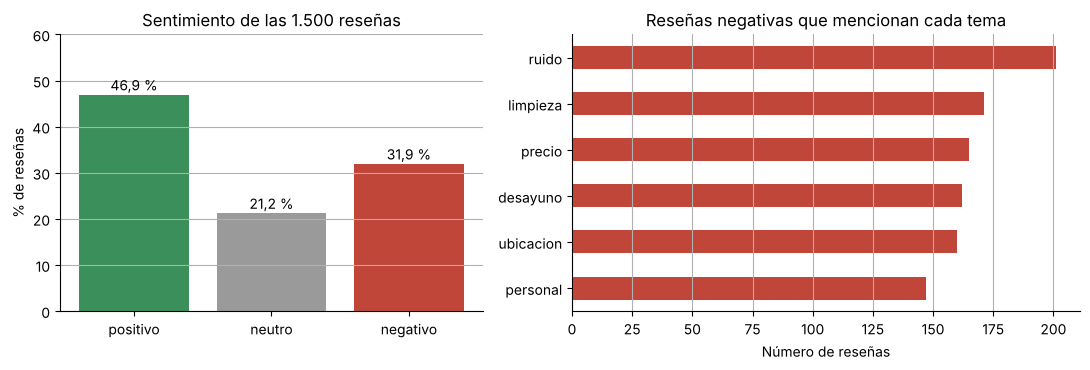

In [10]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.2]})
colores = {"positivo": "#3b8f5a", "neutro": "#9a9a9a", "negativo": "#c0463a"}
ejes[0].bar(ORDEN, reparto.values, color=[colores[s] for s in ORDEN])
for i, v in enumerate(reparto.values):
    ejes[0].text(i, v + 1, f"{v:.1f} %".replace(".", ","), ha="center")
ejes[0].set_title("Sentimiento de las 1.500 reseñas"); ejes[0].set_ylabel("% de reseñas"); ejes[0].set_ylim(0, 60)
quejas.sort_values().plot.barh(ax=ejes[1], color="#c0463a")
ejes[1].set_title("Reseñas negativas que mencionan cada tema"); ejes[1].set_xlabel("Número de reseñas"); ejes[1].set_ylabel("")
ejes[0].grid(axis="x", visible=False); ejes[1].grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig("grafico_resenas.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Expresiones repetidas (n-gramas)

In [11]:
RELLENO = PALABRAS_VACIAS | {"pasamos", "semana", "aquí", "escapada", "fin", "viajamos", "familia", "fuimos", "trabajo", "general", "todo"}

def sin_relleno(texto):
    return " ".join(t for t in limpiar(texto).split() if t not in RELLENO)

def top_ngramas(textos, n=(2, 3), k=5):
    cv = CountVectorizer(preprocessor=sin_relleno, ngram_range=n, min_df=5)
    M = cv.fit_transform(textos)
    frec = pd.Series(np.asarray(M.sum(axis=0)).ravel(), index=cv.get_feature_names_out())
    return frec.sort_values(ascending=False).head(k)

ngramas_neg = top_ngramas(neg["texto"])
print("Expresiones que más se repiten en las reseñas negativas:")
print(ngramas_neg.to_string())

Expresiones que más se repiten en las reseñas negativas:
constante noche          69
ruido constante          69
ruido constante noche    69
ruidosa poco             61
ruidosa poco segura      61


## 8. Cifras para el informe y versiones

In [12]:
import json, sys, sklearn
cifras = {
    "n": int(len(resenas)), "n_test": int(len(X_test)),
    "reparto": reparto.to_dict(), "n_por_clase": resenas["sentimiento"].value_counts().to_dict(),
    "acc_lr": round(acc_lr, 3), "acc_nb": round(acc_nb, 3), "acc_mayoritaria": round(acc_mayoritaria, 3),
    "por_clase": {c: {k: round(informe_clf[c][k], 2) for k in ("precision", "recall", "f1-score")} | {"n": int(informe_clf[c]["support"])} for c in ORDEN},
    "matriz": matriz.tolist(), "falla_negacion": bool(falla_negacion),
    "negacion": dict(zip(pruebas, [str(p) for p in predichas])),
    "f1_temas": f1_por_tema.round(2).to_dict(),
    "n_neg": int(len(neg)), "n_pos": int(len(pos)),
    "temas": tabla_temas.to_dict(orient="index"),
    "quejas": {k: int(v) for k, v in quejas.items()}, "elogios": {k: int(v) for k, v in elogios.items()},
    "criticados": criticados, "valorados": valorados, "citas": citas,
    "ngramas_neg": {k: int(v) for k, v in ngramas_neg.items()},
    "pii": pii_encontrados,
    "versiones": f"Python {sys.version.split()[0]}, numpy {np.__version__}, pandas {pd.__version__}, scikit-learn {sklearn.__version__}",
}
print(json.dumps(cifras, ensure_ascii=False))

{"n": 1500, "n_test": 375, "reparto": {"positivo": 46.9, "neutro": 21.2, "negativo": 31.9}, "n_por_clase": {"positivo": 704, "negativo": 478, "neutro": 318}, "acc_lr": 0.992, "acc_nb": 0.989, "acc_mayoritaria": 0.469, "por_clase": {"positivo": {"precision": 1.0, "recall": 1.0, "f1-score": 1.0, "n": 176}, "neutro": {"precision": 1.0, "recall": 0.96, "f1-score": 0.98, "n": 79}, "negativo": {"precision": 0.98, "recall": 1.0, "f1-score": 0.99, "n": 120}}, "matriz": [[176, 0, 0], [0, 76, 3], [0, 0, 120]], "falla_negacion": true, "negacion": {"La limpieza es impecable": "positivo", "La limpieza no es impecable": "positivo", "El personal fue borde": "negativo", "El personal no fue borde": "negativo", "Vistas increíbles pero un ruido constante": "negativo"}, "f1_temas": {"ruido": 0.94, "limpieza": 1.0, "desayuno": 1.0, "personal": 1.0, "ubicacion": 1.0, "precio": 1.0}, "n_neg": 478, "n_pos": 704, "temas": {"ruido": {"negativas": 201, "positivas": 244, "% negativas": 45.2}, "limpieza": {"negati